# Exploración y Extracción de Datos Reales (GroceryDB)
Este notebook tiene como objetivo cargar la base de datos completa `UpdatedProductIngredients_11_15.json` en memoria, explorar la estructura de llaves utilizada por los autores y extraer el grafo topológico de un producto real para validar el flujo de preprocesamiento.

---
### 1. Carga del JSON masivo
Cargamos el archivo y verificamos cuántos productos contiene exactamente.

In [5]:
import json

# Ruta al archivo real dentro de la carpeta data
ruta_json = "../data/UpdatedProductIngredients_11_15.json"

# Cargamos el JSON
with open(ruta_json, 'r', encoding='utf-8') as archivo:
    base_datos_grocery = json.load(archivo)

print(f"Total de productos cargados exitosamente: {len(base_datos_grocery)}")

# Extraemos el primer producto (índice 0)
producto_real = base_datos_grocery[50]

print("\nEstructura de llaves del producto real:")
print(producto_real.keys())

Total de productos cargados exitosamente: 42541

Estructura de llaves del producto real:
dict_keys(['_id', 'product_name', 'store', 'url', 'original_ID', 'ingredient_tree'])


### 2. Inspección del Árbol de Ingredientes
Antes de construir el grafo completo, inspeccionamos el primer elemento dentro de `ingredient_tree` para confirmar cómo se llaman las llaves internas de cada ingrediente y verificar su nivel de anidación.

In [6]:
# Confirmamos la estructura interna del primer ingrediente del producto
if len(producto_real["ingredient_tree"]) > 0:
    print("Estructura del primer nodo de ingrediente:")
    print(producto_real["ingredient_tree"][0])
else:
    print("Este producto tiene la lista de ingredientes vacía.")

Estructura del primer nodo de ingrediente:
{'original_text': 'hempmilk', 'ingredient_name': 'hempmilk', 'general_name': 'hempmilk', 'ingredient_type': 'ingredient', 'additive_id': None, 'semantic_tree_node': None, 'semantic_tree_name': None, 'order': 1, 'descriptors': [], 'sub_ingredients': [{'original_text': 'water', 'ingredient_name': 'water', 'general_name': 'water', 'ingredient_type': 'ingredient', 'additive_id': None, 'semantic_tree_node': None, 'semantic_tree_name': None, 'order': 1, 'descriptors': [], 'sub_ingredients': []}, {'original_text': 'hemp seed', 'ingredient_name': 'hemp seed', 'general_name': 'hemp seed', 'ingredient_type': 'ingredient', 'additive_id': None, 'semantic_tree_node': None, 'semantic_tree_name': None, 'order': 2, 'descriptors': [], 'sub_ingredients': []}]}


### 3. Construcción Topológica del Producto Real
Recorremos recursivamente el `ingredient_tree` del producto real usando `networkx`. Extraemos también el `original_ID`, que servirá como llave primaria para cruzar este grafo con su puntaje `f_FPro` en el archivo CSV.

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

# Inicializamos el grafo dirigido
G_real = nx.DiGraph()

def construir_grafo_real(lista_ingredientes, nodo_padre=None):
    """
    Recorre recursivamente el árbol real de GroceryDB y construye nodos y aristas.
    """
    for ingrediente in lista_ingredientes:
        nombre_nodo = ingrediente.get("ingredient_name", "Desconocido")
        
        G_real.add_node(nombre_nodo)
        if nodo_padre:
            G_real.add_edge(nodo_padre, nombre_nodo)
            
        sub = ingrediente.get("sub_ingredients", [])
        if len(sub) > 0:
            construir_grafo_real(sub, nodo_padre=nombre_nodo)

# Asignamos el nombre del producto como nodo raíz
nombre_producto = producto_real.get("product_name", "Producto Real 0")
G_real.add_node(nombre_producto)

# Ejecutamos la construcción
lista_principal = producto_real.get("ingredient_tree", [])
construir_grafo_real(lista_principal, nodo_padre=nombre_producto)

print(f"Producto: {nombre_producto}")
print(f"ID Original (llave para CSV): {producto_real.get('original_ID')}")
print(f"Total de Nodos extraídos: {G_real.number_of_nodes()}")
print(f"Total de Aristas extraídas: {G_real.number_of_edges()}")

Producto: Barista Blend Hemp Creamer, 32 fl oz
ID Original (llave para CSV): wf_califia-farms-barista-blend-hemp-creamer-32-fl-oz-b08nyv4f52
Total de Nodos extraídos: 13
Total de Aristas extraídas: 12


### 4. Visualización Jerárquica del Grafo Real
Calculamos la profundidad de cada ingrediente respecto al nodo raíz y graficamos el árbol resultante utilizando el diseño multipartito.

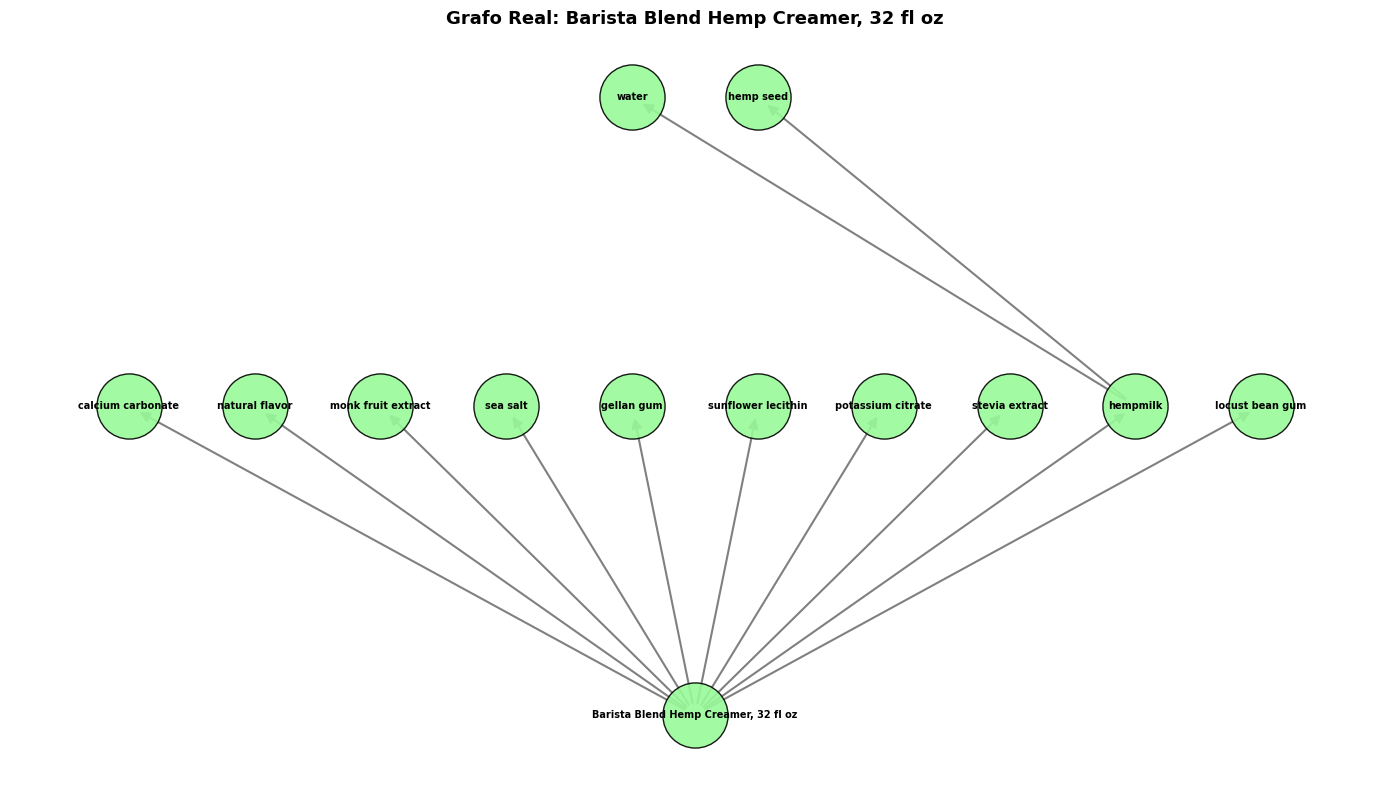

In [8]:
plt.figure(figsize=(14, 8))
plt.title(f"Grafo Real: {nombre_producto}", fontsize=13, fontweight='bold')

# Asignamos la capa según la distancia desde el nodo raíz
for nodo in G_real.nodes():
    try:
        G_real.nodes[nodo]['capa'] = nx.shortest_path_length(G_real, source=nombre_producto, target=nodo)
    except nx.NetworkXNoPath:
        G_real.nodes[nodo]['capa'] = 0

pos_real = nx.multipartite_layout(G_real, subset_key="capa", align="horizontal")

# Dibujamos nodos, aristas y etiquetas
nx.draw_networkx_nodes(G_real, pos_real, node_color='#98FB98', node_size=2200, alpha=0.9, edgecolors='black')
nx.draw_networkx_edges(G_real, pos_real, edge_color='gray', arrows=True, arrowsize=15, width=1.5)
nx.draw_networkx_labels(G_real, pos_real, font_size=7, font_weight="bold")

plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
import json

# Imprimimos el árbol crudo del producto 50 con indentación para que sea legible
print(json.dumps(base_datos_grocery[50]["ingredient_tree"], indent=4, ensure_ascii=False))

[
    {
        "original_text": "hempmilk",
        "ingredient_name": "hempmilk",
        "general_name": "hempmilk",
        "ingredient_type": "ingredient",
        "additive_id": null,
        "semantic_tree_node": null,
        "semantic_tree_name": null,
        "order": 1,
        "descriptors": [],
        "sub_ingredients": [
            {
                "original_text": "water",
                "ingredient_name": "water",
                "general_name": "water",
                "ingredient_type": "ingredient",
                "additive_id": null,
                "semantic_tree_node": null,
                "semantic_tree_name": null,
                "order": 1,
                "descriptors": [],
                "sub_ingredients": []
            },
            {
                "original_text": "hemp seed",
                "ingredient_name": "hemp seed",
                "general_name": "hemp seed",
                "ingredient_type": "ingredient",
                "additive_id"